# 28. Where missed crashes were lost: signal, judging window, cooldown, budget

When the frozen methods of notebook 16 (M0, M1, VPIN, M3) missed 4% events in the development period (2023-01 to 2026-04), at which stage were they lost? In the notebook 27 case (October 29–30, 2026) the score stayed above the threshold inside the judging window, yet the 240-minute cooldown of an alert issued 12–15 minutes before the window opened covered the whole window. Here I count how often that happens in the development period.

The judging window runs from 240 to 30 minutes before the crash (210 minutes), while the cooldown is 240 minutes. A single alert **240–270 minutes before the crash** can therefore hide the entire judging window of that event (the next alert is possible only after the window closes). With a cooldown of 210 minutes or less, such complete hiding cannot occur.

I classify each event × method into the following stages, for the targets `any` and `pre` (pre-onset warning):

| Stage | Meaning |
|---|---|
| 0 ineligible | (`pre` only) the 1% onset comes before the judging window, so a pre-onset warning is impossible by definition |
| 1 no signal | no minute from 240 minutes before the peak to the crash (`pre`: to the 1% onset) has a score above the threshold |
| 2 outside window | the score crossed only outside the judging window (`pre`: outside the part of the window before the 1% onset) |
| 3 cooldown | it crossed inside the window, but even a rule with only the cooldown and no budget emits no alert in the window |
| 4 budget | the cooldown-only rule catches it, but the actual budget (20 per month, 240 per year) blocks it |
| caught | caught under the actual rule |

I split stage 3 further: **window hidden by an earlier alert** (blind spot) / **signal ended before the cooldown expired** / **alert in the window matched to another event**.

I use the notebook 16 frozen models, thresholds and budget, and my replay of the actual rule reproduces the alerts stored by notebook 16. The cooldown-only and 210-minute-cooldown rules are descriptive comparisons: I do not recalibrate thresholds for them and propose neither as a new rule. I decompose only the development period. On the 2018–2020 holdout, which I use only once, I do not recompute scores and count blind-zone alerts from the **notebook 11 stored alerts only** (post hoc, descriptive). This analysis is descriptive, not confirmatory, since I have already examined the development period many times. I write the results to `cooldown_blind_spots_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
import joblib

OUT = SPOT_BASE / 'cooldown_blind_spots_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
HOLD = SPOT_BASE / 'HOLDOUT_2018_2020_confirmatory_v1'
DNAME = '4pct'
METHODS28 = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']
WIN = LEAD_MAX - LEAD_MIN                                     # judging window length, 210 min
POLICIES = {'actual': dict(B=B, cap=MONTH_CAP, cd=COOLDOWN_MIN),
            'cooldown_only': dict(B=10**9, cap=10**9, cd=COOLDOWN_MIN),
            'actual_cd210': dict(B=B, cap=MONTH_CAP, cd=WIN),
            'cooldown_only_cd210': dict(B=10**9, cap=10**9, cd=WIN)}
BLIND_LO, BLIND_HI = LEAD_MAX, LEAD_MAX + COOLDOWN_MIN - WIN  # an alert with lead in (240, 270] min hides the whole window
for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json'] + [M16 / f'alarms_{m}_{DNAME}.csv' for m in METHODS28]:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebook 16 are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Where missed crashes were lost: signal, window, cooldown, budget (dev 2023-01..2026-04, descriptive)',
        'methods': {m: 'notebook-16 frozen, 4% definition' for m in METHODS28},
        'events': 'notebook-2 4% catalog, dev events with breach in [2023-01-01 + 4h, 2026-05-01)',
        'targets': {'any': 'an alert 30-240 min before the breach (paper rule)', 'pre': 'the matched alert is also before the 1% onset'},
        'stages': {'0 ineligible': 'pre target only: no minute of the window is before the onset',
                   '1 no signal': 'no candidate minute (score >= frozen threshold) from 240 min before the peak to the breach (pre: to the onset)',
                   '2 outside window': 'candidates exist but none inside the window (pre: inside the pre-onset part of the window)',
                   '3 cooldown': 'candidates inside, but the cooldown-only replay (no caps, 240-min cooldown) does not catch the event',
                   '4 budget': 'the cooldown-only replay catches it but the actual budgeted replay does not',
                   'caught': 'the actual budgeted replay catches it'},
        'cooldown_reasons': {'window hidden by an earlier alert': 'the last alert before the first inside candidate keeps the cooldown running past the end of the window part',
                             'signal ended before the cooldown expired': 'the cooldown ends inside the window part but no candidate follows',
                             'alert in window matched another event': 'an alert falls inside but the matching rule gave it to another event'},
        'blind_zone': f'an alert with lead in ({BLIND_LO}, {BLIND_HI}] min before the breach and no alert in the window',
        'policies': {k: f"{'no caps' if v['cap'] > 10**6 else '20/month, 240/yr'}, {v['cd']}-min cooldown" for k, v in POLICIES.items()},
        'policy_note': 'all replays use the notebook-16 frozen thresholds, start on 2023-01-01 and are descriptive; nothing is re-calibrated or selected',
        'holdout': 'notebook-11 stored alerts only: blind-zone count (post hoc, descriptive); no score is recomputed on the holdout',
        'notebook16_spec_sha256': FROZEN16['spec_sha256']}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
(OUT / '28_SPEC.json').write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/cooldown_blind_spots_v1 | spec sha256 867a8b5ad508cc7e


## 1. Score reproduction and alert replays

I reproduce the notebook 16 M0 and M3 scores and regenerate the alerts under four rules.

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EV = VALID & in_period(T, EVAL_START, EVAL_END)
E = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
EVD = events_between(E, EVAL_START, EVAL_END)
Y = label_from_catalog(T, E); TR = train_mask(T, VALID)

S = {}
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = TR & np.isfinite(Xl).all(axis=1)
m0 = new_logit().fit(Xl[okl], Y[okl]); cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
s = np.full(len(T), np.nan); okp = VALID & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
S['M2_VPIN'] = np.where(VALID, F.vpin.to_numpy(float), np.nan)
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']
if sha256_file(SPOT_BASE / cfg3['model_file']) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(SPOT_BASE / cfg3['model_file'])
s = np.full(len(T), np.nan); s[VALID] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[VALID])[:, 1]; S['M3_GBM_rich'] = s
TH = {m: float(FROZEN16['configs'][f'{m}|{DNAME}']['threshold_2022']) for m in METHODS28}
del Xl, F

REP, CAND = {}, {}
for m in METHODS28:
    ok_ = EV & np.isfinite(S[m]); tt = T[ok_]; el = S[m][ok_] >= TH[m]; CAND[m] = tt[el]
    stored = np.sort(pd.to_datetime(pd.read_csv(M16 / f'alarms_{m}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy())
    for p, kw in POLICIES.items():
        REP[(m, p)] = emit_calendar_fast(tt, el, B=kw['B'], cap=kw['cap'], cooldown_min=kw['cd'])
    if not np.array_equal(REP[(m, 'actual')], stored):
        raise RuntimeError(f'GUARD FAIL: actual replay differs from the notebook-16 stored alerts ({m})')
    print(f'{m:18s} threshold {TH[m]:.6g} | candidate minutes {len(CAND[m]):,} | alerts: '
          + ', '.join(f'{p} {len(REP[(m, p)])}' for p in POLICIES))
print(f'PASS: scores reproduce notebook 16 and the actual replay equals the stored alerts ({time.time() - t_:.0f}s); dev events {len(EVD)}')

M0_VF_logit        threshold 0.669899 | candidate minutes 93,059 | alerts: actual 800, cooldown_only 1598, actual_cd210 800, cooldown_only_cd210 1690
M1_vol_threshold   threshold 1.67603 | candidate minutes 92,917 | alerts: actual 800, cooldown_only 1500, actual_cd210 800, cooldown_only_cd210 1587
M2_VPIN            threshold 0.0360009 | candidate minutes 1,654,794 | alerts: actual 800, cooldown_only 6927, actual_cd210 800, cooldown_only_cd210 7916
M3_GBM_rich        threshold 0.113531 | candidate minutes 155,580 | alerts: actual 768, cooldown_only 1975, actual_cd210 776, cooldown_only_cd210 2166
PASS: scores reproduce notebook 16 and the actual replay equals the stored alerts (123s); dev events 83


## 2. Stage decomposition per event

In [3]:
def count_in(arr, lo, hi):
    return int(np.searchsorted(arr, hi, 'right') - np.searchsorted(arr, lo, 'left'))


def first_in(arr, lo, hi):
    i = int(np.searchsorted(arr, lo, 'left'))
    return int(arr[i]) if i < len(arr) and arr[i] <= hi else None


def last_at_or_before(arr, t):
    i = int(np.searchsorted(arr, t, 'right')) - 1
    return int(arr[i]) if i >= 0 else None


Bk = EVD.breach_utc.astype('int64').to_numpy(); On = EVD.onset_1pct_utc.astype('int64').to_numpy(); Pk = EVD.peak_utc.astype('int64').to_numpy()
W0 = Bk - LEAD_MAX * NS; W1 = Bk - LEAD_MIN * NS
PRE_HI = np.minimum(On, W1 + NS) - 1                         # last instant of the pre-onset part of the window
ELIG_PRE = PRE_HI >= W0
MATCH = {}
for key, a in REP.items():
    mm = match_events(EVD, a)
    MATCH[key] = {int(r.event_id): (int(r.alarm_utc.value), bool(r.pre1pct)) for r in mm.itertuples()}

rows = []
for i, e in enumerate(EVD.itertuples()):
    eid = int(e.event_id)
    for m in METHODS28:
        cand = CAND[m]
        row = dict(event_id=eid, method=m, breach_utc=e.breach_utc, onset_to_breach_min=(Bk[i] - On[i]) / NS,
                   pre_onset_minutes_in_window=int(max(0, (PRE_HI[i] + 1 - W0[i]) // NS)),
                   window_candidates=count_in(cand, W0[i], W1[i]),
                   pre_window_candidates=count_in(cand, W0[i], PRE_HI[i]) if ELIG_PRE[i] else 0)
        for p in POLICIES:
            hit = MATCH[(m, p)].get(eid)
            row[f'caught_{p}'] = hit is not None; row[f'pre_{p}'] = bool(hit and hit[1])
            a = REP[(m, p)]
            row[f'blind_zone_{p}'] = (count_in(a, Bk[i] - BLIND_HI * NS, Bk[i] - BLIND_LO * NS - 1) > 0) and count_in(a, W0[i], W1[i]) == 0
        cd_alerts = REP[(m, 'cooldown_only')]
        for tgt in ('any', 'pre'):
            lo, hi = W0[i], (W1[i] if tgt == 'any' else PRE_HI[i])
            sig_hi = Bk[i] if tgt == 'any' else On[i] - 1
            caught_act = row['caught_actual'] if tgt == 'any' else row['pre_actual']
            caught_cd = row['caught_cooldown_only'] if tgt == 'any' else row['pre_cooldown_only']
            reason, lead_block = '', np.nan
            if caught_act:
                stage = 'caught'
            elif tgt == 'pre' and not ELIG_PRE[i]:
                stage = '0 ineligible'
            elif count_in(cand, Pk[i] - LEAD_MAX * NS, sig_hi) == 0:
                stage = '1 no signal'
            elif count_in(cand, lo, hi) == 0:
                stage = '2 outside window'
            elif not caught_cd:
                stage = '3 cooldown'
                c_star = first_in(cand, lo, hi); a_ = last_at_or_before(cd_alerts, c_star)
                if first_in(cd_alerts, lo, hi) is not None:
                    reason = 'alert in window matched another event'
                elif a_ is not None and a_ + COOLDOWN_MIN * NS > hi:
                    reason = 'window hidden by an earlier alert'; lead_block = (Bk[i] - a_) / NS
                else:
                    reason = 'signal ended before the cooldown expired'
                    if a_ is not None:
                        lead_block = (Bk[i] - a_) / NS
            else:
                stage = '4 budget'
            row[f'stage_{tgt}'] = stage; row[f'cooldown_reason_{tgt}'] = reason; row[f'blocking_alert_lead_min_{tgt}'] = lead_block
        rows.append(row)
EVS = pd.DataFrame(rows); EVS.to_csv(OUT / '1_event_stages.csv', index=False)       # timestamps and counts only, no prices

STAGES = {'any': ['1 no signal', '2 outside window', '3 cooldown', '4 budget', 'caught'],
          'pre': ['0 ineligible', '1 no signal', '2 outside window', '3 cooldown', '4 budget', 'caught']}
st_rows = []
for m in METHODS28:
    x = EVS[EVS.method == m]
    for tgt, order in STAGES.items():
        vc = x[f'stage_{tgt}'].value_counts()
        r = dict(method=m, target=tgt, events=len(x), **{s_: int(vc.get(s_, 0)) for s_ in STAGES['pre']})   # '0 ineligible' is always 0 for 'any'
        cdx = x[x[f'stage_{tgt}'] == '3 cooldown']
        for rs in ['window hidden by an earlier alert', 'signal ended before the cooldown expired', 'alert in window matched another event']:
            r[f'cooldown: {rs}'] = int((cdx[f'cooldown_reason_{tgt}'] == rs).sum())
        hid = cdx[cdx[f'cooldown_reason_{tgt}'] == 'window hidden by an earlier alert']
        r['cooldown: hidden, blocking alert 240-270 min before breach'] = int(((hid[f'blocking_alert_lead_min_{tgt}'] > BLIND_LO) & (hid[f'blocking_alert_lead_min_{tgt}'] <= BLIND_HI)).sum())
        r['cooldown cases caught by cooldown_only_cd210'] = int(cdx['caught_cooldown_only_cd210' if tgt == 'any' else 'pre_cooldown_only_cd210'].sum())
        st_rows.append(r)
STG = pd.DataFrame(st_rows); STG.to_csv(OUT / '2_stage_counts.csv', index=False)
display(STG)

,method,target,events,0 ineligible,1 no signal,2 outside window,3 cooldown,4 budget,caught,cooldown: window hidden by an earlier alert,cooldown: signal ended before the cooldown expired,cooldown: alert in window matched another event,"cooldown: hidden, blocking alert 240-270 min before breach",cooldown cases caught by cooldown_only_cd210
0,M0_VF_logit,any,83,0,2,13,8,21,39,7,1,0,7,6
1,M0_VF_logit,pre,83,0,32,12,10,7,22,9,1,0,7,1
2,M1_vol_threshold,any,83,0,2,14,7,22,38,5,2,0,5,6
3,M1_vol_threshold,pre,83,0,34,13,10,6,20,8,2,0,5,2
4,M2_VPIN,any,83,0,2,0,8,60,13,8,0,0,8,8
5,M2_VPIN,pre,83,0,3,0,33,38,9,33,0,0,9,9
6,M3_GBM_rich,any,83,0,0,6,11,40,26,9,2,0,9,8
7,M3_GBM_rich,pre,83,0,26,10,25,15,7,19,6,0,9,5


## 3. Events caught and blind-zone alerts by rule

`blind_zone_events`: events with an alert 240–270 minutes before the crash and no alert inside the judging window (under that rule), that is, events where a single alert hid the whole window. The rules issue different numbers of alerts, so in the comparison with the 210-minute-cooldown rule I also use values per 100 alerts; I do not recalibrate thresholds.

In [4]:
pr = []
for m in METHODS28:
    x = EVS[EVS.method == m]
    for p in POLICIES:
        n_a = len(REP[(m, p)]); c_any = int(x[f'caught_{p}'].sum()); c_pre = int(x[f'pre_{p}'].sum())
        pr.append(dict(method=m, policy=p, alerts=n_a, caught_any=c_any, caught_pre=c_pre,
                       caught_any_per_100_alerts=100 * c_any / n_a if n_a else np.nan, caught_pre_per_100_alerts=100 * c_pre / n_a if n_a else np.nan,
                       blind_zone_events=int(x[f'blind_zone_{p}'].sum()),
                       blind_zone_share_of_misses=float(x[f'blind_zone_{p}'].sum() / max(1, (~x[f'caught_{p}']).sum()))))
POLT = pd.DataFrame(pr); POLT.to_csv(OUT / '3_policy_catches_blind_zone.csv', index=False)
display(POLT.round(3))
# events gained or lost when only the cooldown changes (same budget, same threshold)
gl = []
for m in METHODS28:
    x = EVS[EVS.method == m]
    for tgt, col in [('any', 'caught'), ('pre', 'pre')]:
        a_, b_ = x[f'{col}_actual'], x[f'{col}_actual_cd210']
        gl.append(dict(method=m, target=tgt, actual=int(a_.sum()), actual_cd210=int(b_.sum()), gained=int((~a_ & b_).sum()), lost=int((a_ & ~b_).sum())))
GL = pd.DataFrame(gl); GL.to_csv(OUT / '3b_cooldown210_gained_lost.csv', index=False); display(GL)

,method,policy,alerts,caught_any,caught_pre,caught_any_per_100_alerts,caught_pre_per_100_alerts,blind_zone_events,blind_zone_share_of_misses
0,M0_VF_logit,actual,800,39,22,4.875,2.750,3,0.068
1,M0_VF_logit,cooldown_only,1598,60,29,3.755,1.815,7,0.304
2,M0_VF_logit,actual_cd210,800,38,20,4.750,2.500,1,0.022
3,M0_VF_logit,cooldown_only_cd210,1690,66,29,3.905,1.716,1,0.059
4,M1_vol_threshold,actual,800,38,20,4.750,2.500,2,0.044
5,M1_vol_threshold,cooldown_only,1500,60,26,4.000,1.733,5,0.217
6,M1_vol_threshold,actual_cd210,800,38,20,4.750,2.500,0,0.000
7,M1_vol_threshold,cooldown_only_cd210,1587,66,27,4.159,1.701,0,0.000
8,M2_VPIN,actual,800,13,9,1.625,1.125,0,0.000
9,M2_VPIN,cooldown_only,6927,71,42,1.025,0.606,10,0.833


,method,target,actual,actual_cd210,gained,lost
0,M0_VF_logit,any,39,38,2,3
1,M0_VF_logit,pre,22,20,0,2
2,M1_vol_threshold,any,38,38,3,3
3,M1_vol_threshold,pre,20,20,1,1
4,M2_VPIN,any,13,12,0,1
5,M2_VPIN,pre,9,6,0,3
6,M3_GBM_rich,any,26,28,3,1
7,M3_GBM_rich,pre,7,7,2,2


## 4. Bitcoin holdout 2018–2020: blind-zone alerts counted from notebook 11 stored alerts (post hoc, descriptive)

Here I use only the stored alerts and event times. I do not recompute scores, and the holdout reading of notebook 11 stays unchanged.

In [5]:
HZ = None
try:
    hev = pd.read_csv(HOLD / 'holdout_events.csv')
    for c_ in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        hev[c_] = pd.to_datetime(hev[c_], utc=True)
    hev = hev.sort_values('breach_utc').reset_index(drop=True)
    ah = np.sort(pd.to_datetime(pd.read_csv(HOLD / 'alarms_calendar.csv').alarm_utc, utc=True).astype('int64').to_numpy())
    H1 = json.loads((HOLD / 'HOLDOUT_RESULTS.json').read_text())['H1']
    sth = statistics(hev, ah)
    if [sth['alarms'], sth['caught'], sth['before_1pct']] != [H1['alarms'], H1['any_hits'], H1['pre_onset_hits']]:
        raise RuntimeError('GUARD FAIL: saved holdout alerts/events do not reproduce notebook 11')
    hm = match_events(hev, ah); caught_h = set(hm.event_id.astype(int))
    hb = hev.breach_utc.astype('int64').to_numpy()
    bz = [(count_in(ah, b - BLIND_HI * NS, b - BLIND_LO * NS - 1) > 0) and count_in(ah, b - LEAD_MAX * NS, b - LEAD_MIN * NS) == 0 for b in hb]
    missed = [int(e) not in caught_h for e in hev.event_id]
    HZ = dict(events=len(hev), alerts=len(ah), caught=len(caught_h), missed=int(sum(missed)), blind_zone_events=int(sum(bz)),
              blind_zone_share_of_misses=float(sum(bz) / max(1, sum(missed))))
    print('holdout (notebook-11 stored M0 alerts, post hoc):', HZ)
except FileNotFoundError as e_:
    print(f'holdout files not found ({e_}); section skipped')

holdout (notebook-11 stored M0 alerts, post hoc): {'events': 199, 'alerts': 713, 'caught': 36, 'missed': 163, 'blind_zone_events': 3, 'blind_zone_share_of_misses': 0.018404907975460124}


## 5. Figures and summary

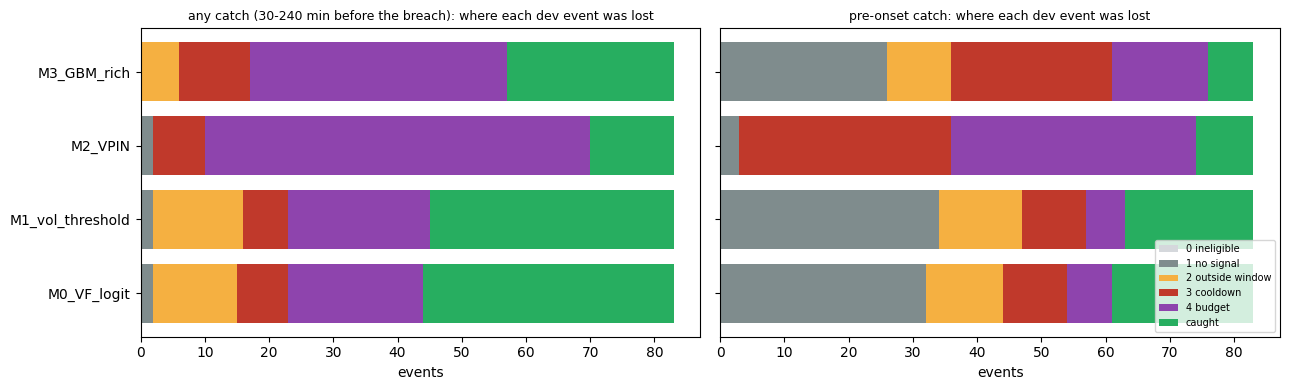

M0_VF_logit        any | 1 no signal 2 | 2 outside window 13 | 3 cooldown 8 | 4 budget 21 | caught 39 | cooldown: hidden 7 (240-270 min: 7), signal ended 1, other 0 | caught with a 210-min cooldown: 6
M0_VF_logit        pre | 0 ineligible 0 | 1 no signal 32 | 2 outside window 12 | 3 cooldown 10 | 4 budget 7 | caught 22 | cooldown: hidden 9 (240-270 min: 7), signal ended 1, other 0 | caught with a 210-min cooldown: 1
M1_vol_threshold   any | 1 no signal 2 | 2 outside window 14 | 3 cooldown 7 | 4 budget 22 | caught 38 | cooldown: hidden 5 (240-270 min: 5), signal ended 2, other 0 | caught with a 210-min cooldown: 6
M1_vol_threshold   pre | 0 ineligible 0 | 1 no signal 34 | 2 outside window 13 | 3 cooldown 10 | 4 budget 6 | caught 20 | cooldown: hidden 8 (240-270 min: 5), signal ended 2, other 0 | caught with a 210-min cooldown: 2
M2_VPIN            any | 1 no signal 2 | 2 outside window 0 | 3 cooldown 8 | 4 budget 60 | caught 13 | cooldown: hidden 8 (240-270 min: 8), signal ended 0, othe

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
colors = {'0 ineligible': '#d5d8dc', '1 no signal': '#7f8c8d', '2 outside window': '#f5b041', '3 cooldown': '#c0392b', '4 budget': '#8e44ad', 'caught': '#27ae60'}
for ax, tgt in zip(axs, ['any', 'pre']):
    x = STG[STG.target == tgt].set_index('method'); left = np.zeros(len(x))
    for s_ in STAGES[tgt]:
        ax.barh(x.index, x[s_], left=left, color=colors[s_], label=s_); left += x[s_].to_numpy()
    ax.set_title(f"{'any catch (30-240 min before the breach)' if tgt == 'any' else 'pre-onset catch'}: where each dev event was lost", fontsize=9)
    ax.set_xlabel('events')
axs[1].legend(fontsize=7, loc='lower right'); plt.tight_layout(); plt.savefig(OUT / '4_stage_counts.png', dpi=140); plt.show()

summary = dict(spec_sha256=SPEC_SHA, status='descriptive; development sample seen before; replays other than "actual" are comparisons, not rules',
               dev_events=len(EVD), thresholds=TH, window_min=WIN, cooldown_min=COOLDOWN_MIN, blind_zone_lead_min=[BLIND_LO, BLIND_HI],
               stage_counts=STG.to_dict('records'), policies=POLT.to_dict('records'), cooldown210_gained_lost=GL.to_dict('records'), holdout_post_hoc=HZ)
(OUT / 'BLIND_SPOT_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=float))
for d in STG.to_dict('records'):
    print(f"{d['method']:18s} {d['target']:3s} | " + ' | '.join(f'{s_} {int(d[s_])}' for s_ in STAGES[d['target']])
          + f" | cooldown: hidden {d['cooldown: window hidden by an earlier alert']} (240-270 min: {d['cooldown: hidden, blocking alert 240-270 min before breach']}),"
          + f" signal ended {d['cooldown: signal ended before the cooldown expired']}, other {d['cooldown: alert in window matched another event']}"
          + f" | caught with a 210-min cooldown: {d['cooldown cases caught by cooldown_only_cd210']}")

## Interpretation
- `2_stage_counts.csv` / last lines: for each method, the stage at which development-period events were lost. `any` is the paper's catch (an alert 30–240 minutes before the crash) and `pre` the subset with the alert before the 1% onset.
  - Many `3 cooldown`: the signal was inside the window but the alert spacing kept the alert out. Among these, `hidden` (an earlier alert hides the whole window) is the type seen in notebook 27, and `240-270 min` counts cases where that hiding alert came exactly 240–270 minutes before the crash (a pure blind spot that exists because the cooldown is longer than the window).
  - Many `4 budget`: the budget of 20 per month and 240 per year is the main bottleneck.
  - Many `1 no signal` or `2 outside window`: the problem lies in the signal itself, not in the operating rules.
- `3_policy_catches_blind_zone.csv`: events caught and blind-zone events by rule. The cooldown-only rule issues far more alerts, so I report values per 100 alerts alongside.
- `3b_cooldown210_gained_lost.csv`: events newly caught or newly missed when I shorten only the cooldown to 210 minutes and keep the budget and thresholds. The alert sequence changes, so some events can be lost. This comparison is descriptive, and I do not use it as grounds to change the preregistered rules.
- Holdout line: blind-zone events that I count from the notebook 11 stored alerts only; this count is post hoc and descriptive, and the notebook 11 reading stays unchanged.